**Lab09_Customer_Segmentation_KMeans**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Machine Learning & Clustering Tools
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Clustering libraries imported successfully!")

Clustering libraries imported successfully!


In [2]:
# Check for dataset path
possible_paths = [
    Path("../data/processed/olist_orders_abt.csv"),
    Path("data/processed/olist_orders_abt.csv"),
    Path("../data/processed/olist_orders_feature_engineered.csv"),
    Path("data/processed/olist_orders_feature_engineered.csv")
]

data_path = None
for p in possible_paths:
    if p.exists():
        temp_df = pd.read_csv(p, nrows=2)
        if "customer_unique_id" in temp_df.columns:
            data_path = p
            break

if data_path is None:
    # If not found, use the first available path
    for p in possible_paths:
        if p.exists():
            data_path = p
            break

df = pd.read_csv(data_path)
print(f"Dataset loaded from: {data_path}")
print("Order-level shape (Rows, Columns):", df.shape)

if "customer_unique_id" not in df.columns:
    raise ValueError("customer_unique_id is required for customer-level segmentation!")

print(f"Total order rows: {len(df)}")
print(f"Unique customers: {df['customer_unique_id'].nunique()}")
df.head(3)

Dataset loaded from: ..\data\processed\olist_orders_abt.csv
Order-level shape (Rows, Columns): (99441, 29)
Total order rows: 99441
Unique customers: 96096


,order_id,customer_id,customer_unique_id,customer_city,customer_state,order_status,order_year,order_month,order_day,order_day_of_week,...,total_payment_value,max_payment_installments,payment_types_count,dominant_payment_type,total_items,total_price,total_freight,unique_products,unique_sellers,main_product_category
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,delivered,2017,10,2,0,...,38.71,1.0,2.0,voucher,1.0,29.99,8.72,1.0,1.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,barreiras,BA,delivered,2018,7,24,1,...,141.46,1.0,1.0,boleto,1.0,118.70,22.76,1.0,1.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,delivered,2018,8,8,2,...,179.12,3.0,1.0,credit_card,1.0,159.90,19.22,1.0,1.0,auto


In [3]:
if "order_purchase_timestamp" in df.columns:
    df["purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"], errors="coerce")
elif all(col in df.columns for col in ["order_year", "order_month", "order_day"]):
    date_parts = pd.DataFrame({
        "year": df["order_year"],
        "month": df["order_month"],
        "day": df["order_day"]
    })
    if "order_hour" in df.columns:
        date_parts["hour"] = df["order_hour"].fillna(0)
    df["purchase_timestamp"] = pd.to_datetime(date_parts, errors="coerce")
else:
    raise ValueError("Could not find order purchase date/time columns!")

df = df.dropna(subset=["customer_unique_id", "purchase_timestamp"]).copy()
print("Purchase timestamps prepared successfully!")
print("Date range in dataset:", df["purchase_timestamp"].min(), "to", df["purchase_timestamp"].max())

Purchase timestamps prepared successfully!
Date range in dataset: 2016-09-04 21:00:00 to 2018-10-17 17:00:00


In [4]:
# 1. Use delivered orders
if "order_status" in df.columns:
    df_work = df[df["order_status"].astype(str).str.lower() == "delivered"].copy()
    if df_work.empty:
        df_work = df.copy()
else:
    df_work = df.copy()

# 2. Select monetary column
monetary_col = "total_payment_value" if "total_payment_value" in df_work.columns else "total_price"
print(f"Monetary column used: {monetary_col}")

# 3. Reference date: 1 day after the latest purchase in the whole dataset
analysis_date = df_work["purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
print(f"Recency reference date: {analysis_date}")

# 4. Aggregation recipe
agg_dict = {
    "purchase_timestamp": ["min", "max", "count"],
    monetary_col: ["sum", "mean"]
}
for col in ["total_freight", "total_items", "unique_products"]:
    if col in df_work.columns:
        agg_dict[col] = "mean"

customer_df = df_work.groupby("customer_unique_id").agg(agg_dict)
customer_df.columns = ["_".join(col).strip() for col in customer_df.columns]
customer_df = customer_df.reset_index()

# 5. Rename columns cleanly
rename_dict = {
    "purchase_timestamp_min": "first_purchase_timestamp",
    "purchase_timestamp_max": "last_purchase_timestamp",
    "purchase_timestamp_count": "frequency",
    f"{monetary_col}_sum": "monetary",
    f"{monetary_col}_mean": "average_order_value",
    "total_freight_mean": "average_freight",
    "total_items_mean": "average_items_per_order",
    "unique_products_mean": "average_unique_products_per_order"
}
customer_df = customer_df.rename(columns=rename_dict)

# 6. Calculate Recency in Days
customer_df["recency_days"] = (analysis_date - customer_df["last_purchase_timestamp"].dt.normalize()).dt.days

print("\nCustomer-Level Data Ready!")
print("Customer table shape (1 row per customer):", customer_df.shape)
customer_df.head(3)

Monetary column used: total_payment_value
Recency reference date: 2018-08-30 00:00:00

Customer-Level Data Ready!
Customer table shape (1 row per customer): (93358, 10)


,customer_unique_id,first_purchase_timestamp,last_purchase_timestamp,frequency,monetary,average_order_value,average_freight,average_items_per_order,average_unique_products_per_order,recency_days
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:00:00,2018-05-10 10:00:00,1,141.90,141.90,12.00,1.0,1.0,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:00:00,2018-05-07 11:00:00,1,27.19,27.19,8.29,1.0,1.0,115
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:00:00,2017-03-10 21:00:00,1,86.22,86.22,17.22,1.0,1.0,538


,count,mean,std,min,25%,50%,75%,max
recency_days,93358.0,238.478877,152.595054,1.00,115.0000,219.00,347.0000,714.00
frequency,93358.0,1.033420,0.209097,1.00,1.0000,1.00,1.0000,15.00
monetary,93358.0,165.197003,226.314012,0.00,63.0525,107.78,182.5575,13664.08
average_order_value,93357.0,160.316648,219.572062,9.59,62.3700,105.63,176.6500,13664.08



Order frequency counts (Most customers buy only once!):
frequency
1    90557
2     2573
3      181
4       28
5        9
Name: count, dtype: int64


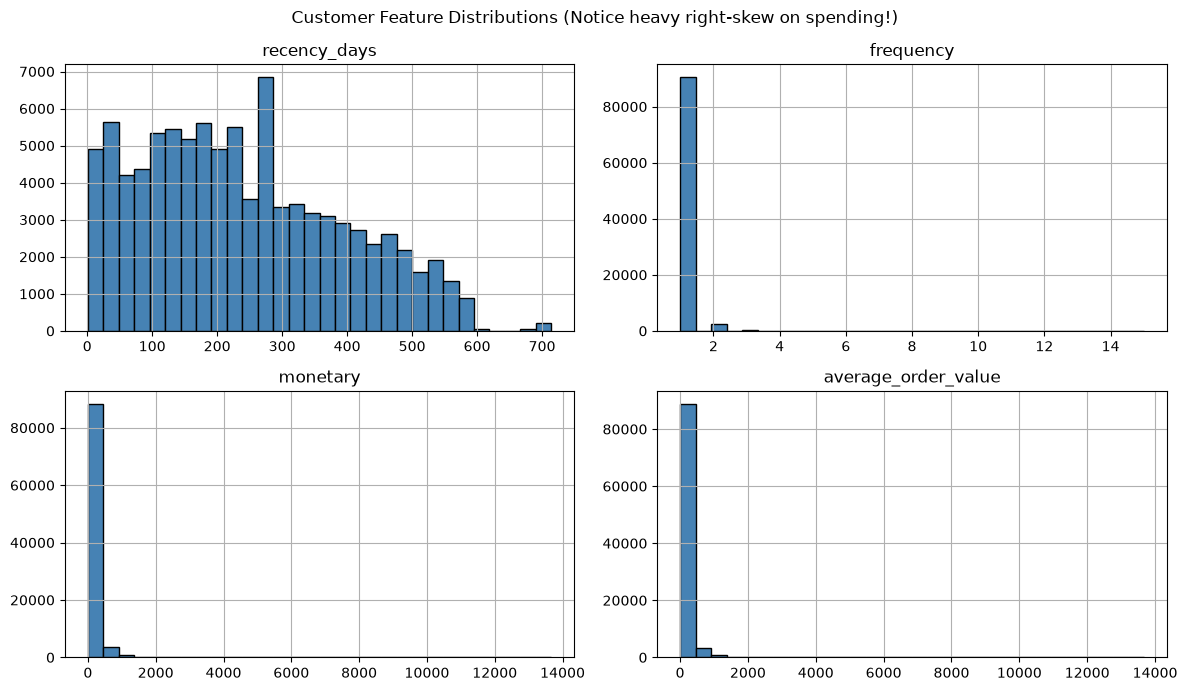

In [5]:
base_features = ["recency_days", "frequency", "monetary", "average_order_value"]
display(customer_df[base_features].describe().T)

print("\nOrder frequency counts (Most customers buy only once!):")
print(customer_df["frequency"].value_counts().head(5))

# Plot feature distributions
customer_df[base_features].hist(bins=30, figsize=(12, 7), color="steelblue", edgecolor="black")
plt.suptitle("Customer Feature Distributions (Notice heavy right-skew on spending!)")
plt.tight_layout()
plt.show()

In [6]:
candidate_features = [
    "recency_days", "frequency", "monetary",
    "average_order_value", "average_freight", "average_items_per_order"
]
features = [c for c in candidate_features if c in customer_df.columns]

X_raw = customer_df[features].copy()
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.fillna(X_raw.median(numeric_only=True))

# Align customer_df
customer_df = customer_df.loc[X_raw.index].copy()

# 1. Skewness Reduction via log1p
X_transformed = X_raw.copy()
for col in ["monetary", "average_order_value", "average_freight", "average_items_per_order"]:
    if col in X_transformed.columns:
        X_transformed[col] = np.log1p(X_transformed[col].clip(lower=0))

# 2. Standardization (Mean=0, Std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

print(f"Features ready for clustering ({len(features)}):", features)
print("Scaled matrix shape:", X_scaled.shape)

Features ready for clustering (6): ['recency_days', 'frequency', 'monetary', 'average_order_value', 'average_freight', 'average_items_per_order']
Scaled matrix shape: (93358, 6)


Evaluating candidate values of k from 2 to 8...


,k,inertia,silhouette_score
0,2,410876.081663,0.310615
1,3,336208.965069,0.331432
2,4,269097.271676,0.324363
3,5,228765.903797,0.291862
4,6,199107.909742,0.287656
5,7,181909.903578,0.274272
6,8,166957.844537,0.281610


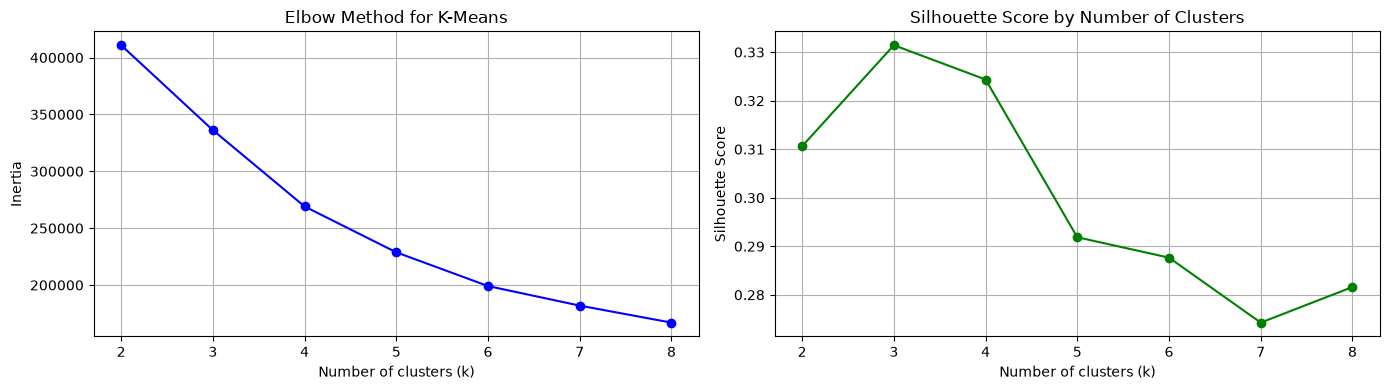

In [7]:
k_values = range(2, 9)
k_results = []

print("Evaluating candidate values of k from 2 to 8...")
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    
    # Sample 5,000 customers for fast silhouette calculation
    sil = silhouette_score(X_scaled, labels, sample_size=min(5000, len(labels)), random_state=42)
    k_results.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette_score": sil
    })

k_results_df = pd.DataFrame(k_results)
display(k_results_df)

# Plot Elbow and Silhouette curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(k_results_df["k"], k_results_df["inertia"], marker="o", color="blue")
axes[0].set_title("Elbow Method for K-Means")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(k_results_df["k"], k_results_df["silhouette_score"], marker="o", color="green")
axes[1].set_title("Silhouette Score by Number of Clusters")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [8]:
chosen_k = 4

final_kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
customer_df["cluster"] = final_kmeans.fit_predict(X_scaled)

cluster_counts = customer_df["cluster"].value_counts().sort_index().to_frame("customer_count")
cluster_counts["percentage"] = (cluster_counts["customer_count"] / len(customer_df) * 100).round(2)

print(f"K-Means fitted with k = {chosen_k}!")
display(cluster_counts)

K-Means fitted with k = 4!


,customer_count,percentage
cluster,,
0,34390,36.84
1,8513,9.12
2,2777,2.97
3,47678,51.07


In [9]:
profile_features = [c for c in features if c in customer_df.columns]

cluster_medians = customer_df.groupby("cluster")[profile_features].median().round(2)
display(cluster_counts.join(cluster_medians))

,customer_count,percentage,recency_days,frequency,monetary,average_order_value,average_freight,average_items_per_order
cluster,,,,,,,,
0,34390,36.84,211.0,1.0,184.06,184.06,21.33,1.0
1,8513,9.12,222.0,1.0,177.44,177.32,35.26,2.0
2,2777,2.97,200.0,2.0,224.57,108.87,17.86,1.0
3,47678,51.07,225.0,1.0,64.10,64.10,14.84,1.0


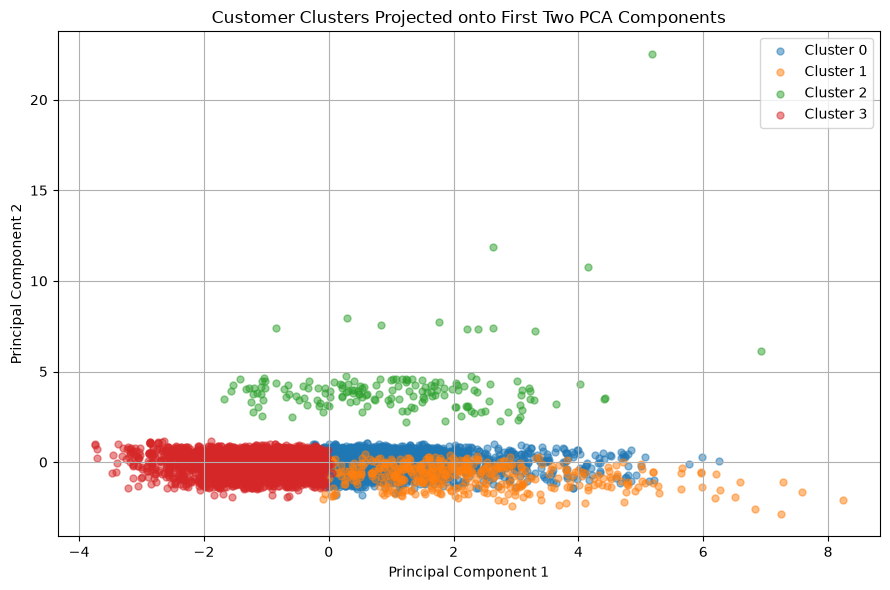

Variance explained by 2 PCA components: 60.3%


In [10]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": customer_df["cluster"].values
})

# Sample 5,000 for clean visualization
sample_plot = plot_df.sample(min(5000, len(plot_df)), random_state=42)

plt.figure(figsize=(9, 6))
for c_id in sorted(sample_plot["cluster"].unique()):
    subset = sample_plot[sample_plot["cluster"] == c_id]
    plt.scatter(subset["PC1"], subset["PC2"], label=f"Cluster {c_id}", alpha=0.5, s=25)

plt.title("Customer Clusters Projected onto First Two PCA Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Variance explained by 2 PCA components: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

In [11]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

customer_path = output_dir / "olist_customer_segments.csv"
profile_path = output_dir / "olist_customer_cluster_profile.csv"

try:
    customer_df.to_csv(customer_path, index=False)
    cluster_medians.to_csv(profile_path)
except Exception:
    customer_path = Path("data/processed/olist_customer_segments.csv")
    profile_path = Path("data/processed/olist_customer_cluster_profile.csv")
    customer_df.to_csv(customer_path, index=False)
    cluster_medians.to_csv(profile_path)

print(f"Customer segments saved to: {customer_path}")
print(f"Cluster profile saved to: {profile_path}")

Customer segments saved to: ..\data\processed\olist_customer_segments.csv
Cluster profile saved to: ..\data\processed\olist_customer_cluster_profile.csv
